In [ ]:
!pip install opendatasets
import opendatasets as od
od.download("https://www.kaggle.com/datasets/noamaanabdulazeem/jmuben-coffee-dataset")

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: ayaanmdblr
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/noamaanabdulazeem/jmuben-coffee-dataset


100%|██████████| 773M/773M [00:09<00:00, 85.4MB/s]


In [ ]:
import os
import shutil

# Define the source folder created by opendatasets and the target base directory
source_dataset_folder = "jmuben-coffee-dataset"
target_data_base_path = "data"

# Create the 'data' directory if it doesn't exist
os.makedirs(target_data_base_path, exist_ok=True)

# Define the final expected path for the dataset
destination_path = os.path.join(target_data_base_path, source_dataset_folder)

# Check if the source exists and destination doesn't to avoid errors if run multiple times
if os.path.exists(source_dataset_folder) and not os.path.exists(destination_path):
    shutil.move(source_dataset_folder, target_data_base_path)
    print(f"Moved '{{source_dataset_folder}}' to '{{destination_path}}'")
elif os.path.exists(destination_path):
    print(f"'{{destination_path}}' already exists. Skipping move operation.")
else:
    print(f"Source folder '{{source_dataset_folder}}' not found. Ensure opendatasets downloaded correctly.")

# Verify the structure for the next steps
print(f"Contents of '{{target_data_base_path}}' directory after move:")
for root, dirs, files in os.walk(target_data_base_path):
    print(root)


Moved '{source_dataset_folder}' to '{destination_path}'
Contents of '{target_data_base_path}' directory after move:
data
data/jmuben-coffee-dataset
data/jmuben-coffee-dataset/JMuBEN
data/jmuben-coffee-dataset/JMuBEN/Miner
data/jmuben-coffee-dataset/JMuBEN/Cerscospora
data/jmuben-coffee-dataset/JMuBEN/Leaf rust
data/jmuben-coffee-dataset/JMuBEN/Phoma
data/jmuben-coffee-dataset/JMuBEN/Healthy


In [ ]:
import os

data_path = "data"

for root, dirs, files in os.walk(data_path):
    print(root)

data
data/jmuben-coffee-dataset
data/jmuben-coffee-dataset/JMuBEN
data/jmuben-coffee-dataset/JMuBEN/Miner
data/jmuben-coffee-dataset/JMuBEN/Cerscospora
data/jmuben-coffee-dataset/JMuBEN/Leaf rust
data/jmuben-coffee-dataset/JMuBEN/Phoma
data/jmuben-coffee-dataset/JMuBEN/Healthy


In [ ]:
from pathlib import Path

# Set the root to the extracted coffee dataset directory.
# Based on opendatasets download, the structure is 'data/jmuben-coffee-dataset/JMuBEN/{class_folders}'.
img_root = Path("data/jmuben-coffee-dataset/JMuBEN")

# Basic check to ensure the path exists and contains directories
if not img_root.exists() or not any(p.is_dir() for p in img_root.iterdir()):
    raise RuntimeError(f"Could not locate a folder with class subdirectories at {img_root}. Please inspect its contents.")

print("Using image root:", img_root)
# List the top-level directories within img_root (should be class folders like Miner, Healthy, etc.)
print("Found classes:", [p.name for p in img_root.iterdir() if p.is_dir()])

Using image root: data/jmuben-coffee-dataset/JMuBEN
Found classes: ['Miner', 'Cerscospora', 'Leaf rust', 'Phoma', 'Healthy']


In [ ]:
# Cell 4: Optional — programmatic split into train/val/test
# If your dataset already has train/val/test folders, skip this and set USE_PROGRAMMATIC_SPLIT=False below.
import random
import numpy as np
import shutil

USE_PROGRAMMATIC_SPLIT = True # Set to True as the downloaded dataset does not have pre-defined splits
VAL_SPLIT = 0.15
TEST_SPLIT = 0.10
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

split_root = Path("/content/split") # This will be the root for the new train/val/test folders
train_dir = split_root / "train"
val_dir = split_root / "val"
test_dir = split_root / "test"

def safe_copy_tree(src_dir, dst_dir):
    dst_dir.mkdir(parents=True, exist_ok=True)
    for p in src_dir.iterdir():
        if p.is_dir():
            (dst_dir / p.name).mkdir(exist_ok=True)

# If using programmatic split, ensure previous split directories are cleaned and new ones are created.
if USE_PROGRAMMATIC_SPLIT:
    # Clean up previous split if it exists
    if split_root.exists():
        print(f"Cleaning up existing split directory: {split_root}")
        shutil.rmtree(split_root)

    # Collect files by class from img_root (which now points to 'data/jmuben-coffee-dataset/JMuBEN')
    classes = [p for p in img_root.iterdir() if p.is_dir()]
    for cls in classes:
        images = [p for p in cls.rglob("*") if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png"]]
        random.shuffle(images)
        n = len(images)
        n_val = int(n * VAL_SPLIT)
        n_test = int(n * TEST_SPLIT)
        n_train = n - n_val - n_test

        splits = {
            train_dir / cls.name: images[:n_train],
            val_dir / cls.name: images[n_train:n_train+n_val],
            test_dir / cls.name: images[n_train+n_val:],
        }
        for out_dir, files_ in splits.items():
            out_dir.mkdir(parents=True, exist_ok=True)
            for f in files_:
                # Avoid name collisions by including class name
                dest = out_dir / f.name
                # If collision, prefix with an index
                i = 1
                while dest.exists():
                    dest = out_dir / f"{i}_{f.name}"
                    i += 1
                shutil.copy2(f, dest)

# Print a message indicating whether programmatic split is used
if USE_PROGRAMMATIC_SPLIT:
    print("Split dirs created:",
          train_dir.exists(), val_dir.exists(), test_dir.exists())
else:
    print("Using pre-defined train/val/test splits from the dataset.")

Cleaning up existing split directory: /content/split
Split dirs created: True True True


In [ ]:
# Cell 6: Imports and device
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import DataLoader
import torchvision
from torchvision import datasets, transforms, models

import time, copy
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.metrics import classification_report, confusion_matrix

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


Torch: 2.10.0+cu128
CUDA available: True


In [ ]:
# Cell 7: Transforms and datasets
IMG_SIZE = 128
BATCH_SIZE = 32
NUM_WORKERS = 2  # Colab default: 2 is safe

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.AutoAugment(transforms.AutoAugmentPolicy.IMAGENET),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# Choose source dirs depending on split
if USE_PROGRAMMATIC_SPLIT:
    train_dataset = datasets.ImageFolder(root=train_dir, transform=train_transforms)
    val_dataset   = datasets.ImageFolder(root=val_dir, transform=eval_transforms)
    test_dataset  = datasets.ImageFolder(root=test_dir, transform=eval_transforms)
else:
    # If the dataset already had train/val/test
    pre_split_root = img_root  # adjust if different
    train_dataset = datasets.ImageFolder(root=pre_split_root / "train", transform=train_transforms)
    val_dataset   = datasets.ImageFolder(root=pre_split_root / "val", transform=eval_transforms)
    test_dataset  = datasets.ImageFolder(root=pre_split_root / "test", transform=eval_transforms)

num_classes = len(train_dataset.classes)
class_to_idx = train_dataset.class_to_idx
idx_to_class = {v: k for k, v in class_to_idx.items()}

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)

print("Classes:", train_dataset.classes)
print("Dataset sizes — Train:", len(train_dataset), "Val:", len(val_dataset), "Test:", len(test_dataset))

Classes: ['Cerscospora', 'Healthy', 'Leaf rust', 'Miner', 'Phoma']
Dataset sizes — Train: 43916 Val: 8780 Test: 5853


In [ ]:
# Cell 8: Build ResNet50 and optimizer
# Use pretrained weights; modify final FC layer to match num_classes
resnet50 = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
in_features = resnet50.fc.in_features
resnet50.fc = nn.Linear(in_features, num_classes)

# Option: freeze backbone for quick baseline
FREEZE_BACKBONE = False
if FREEZE_BACKBONE:
    for name, p in resnet50.named_parameters():
        if not name.startswith("fc"):
            p.requires_grad = False

resnet50 = resnet50.to(device)

criterion = nn.CrossEntropyLoss()
LR = 3e-4
WEIGHT_DECAY = 1e-4
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, resnet50.parameters()),
                        lr=LR, weight_decay=WEIGHT_DECAY)
EPOCHS = 15
scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS)

scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


/tmp/ipykernel_904/1501401890.py:24: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


In [ ]:
# Cell 9: Training and validation loops
def train_one_epoch(model, loader, optimizer, criterion, scaler):
    model.train()
    running_loss, running_corrects, total = 0.0, 0, 0

    for inputs, labels in loader:
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
            outputs = model(inputs)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        preds = outputs.argmax(dim=1)
        running_loss += loss.item() * inputs.size(0)
        running_corrects += (preds == labels).sum().item()
        total += inputs.size(0)

    return running_loss / total, running_corrects / total

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    running_loss, running_corrects, total = 0.0, 0, 0
    all_preds, all_labels = [], []

    for inputs, labels in loader:
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        preds = outputs.argmax(dim=1)

        running_loss += loss.item() * inputs.size(0)
        running_corrects += (preds == labels).sum().item()
        total += inputs.size(0)

        all_preds.append(preds.cpu())
        all_labels.append(labels.cpu())

    return running_loss / total, running_corrects / total, torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy()


In [ ]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("Current device:", torch.device("cuda" if torch.cuda.is_available() else "cpu"))
print("GPU name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU detected")


CUDA available: True
Current device: cuda
GPU name: Tesla T4


In [ ]:
# Cell 10: Run training

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_acc = 0.0
best_wts = copy.deepcopy(resnet50.state_dict())

start = time.time()
for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(resnet50, train_loader, optimizer, criterion, scaler)
    val_loss, val_acc, _, _ = evaluate(resnet50, val_loader, criterion)
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    if val_acc > best_acc:
        best_acc = val_acc
        best_wts = copy.deepcopy(resnet50.state_dict())

    print(f"Epoch {epoch+1:02d}/{EPOCHS} | Train {train_acc:.4f} loss {train_loss:.4f} | Val {val_acc:.4f} loss {val_loss:.4f}")

elapsed = (time.time() - start) / 60
print(f"Training complete in {elapsed:.1f} min. Best Val Acc: {best_acc:.4f}")

resnet50.load_state_dict(best_wts)


/tmp/ipykernel_904/1515505138.py:11: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):


Epoch 01/15 | Train 0.9842 loss 0.0550 | Val 1.0000 loss 0.0037
Epoch 02/15 | Train 0.9956 loss 0.0142 | Val 1.0000 loss 0.0001
Epoch 03/15 | Train 0.9959 loss 0.0133 | Val 1.0000 loss 0.0005
Epoch 04/15 | Train 0.9967 loss 0.0104 | Val 0.9997 loss 0.0005
Epoch 05/15 | Train 0.9973 loss 0.0097 | Val 1.0000 loss 0.0000
Epoch 06/15 | Train 0.9983 loss 0.0054 | Val 0.9997 loss 0.0005
Epoch 07/15 | Train 0.9990 loss 0.0039 | Val 1.0000 loss 0.0000
Epoch 08/15 | Train 0.9991 loss 0.0031 | Val 0.9997 loss 0.0014
Epoch 09/15 | Train 0.9996 loss 0.0011 | Val 1.0000 loss 0.0000
Epoch 10/15 | Train 0.9997 loss 0.0012 | Val 1.0000 loss 0.0001
Epoch 11/15 | Train 0.9999 loss 0.0005 | Val 1.0000 loss 0.0000
Epoch 12/15 | Train 1.0000 loss 0.0001 | Val 1.0000 loss 0.0000
Epoch 13/15 | Train 1.0000 loss 0.0000 | Val 1.0000 loss 0.0000
Epoch 14/15 | Train 1.0000 loss 0.0000 | Val 1.0000 loss 0.0000
Epoch 15/15 | Train 0.9999 loss 0.0001 | Val 1.0000 loss 0.0000
Training complete in 27.0 min. Best Val 

<All keys matched successfully>

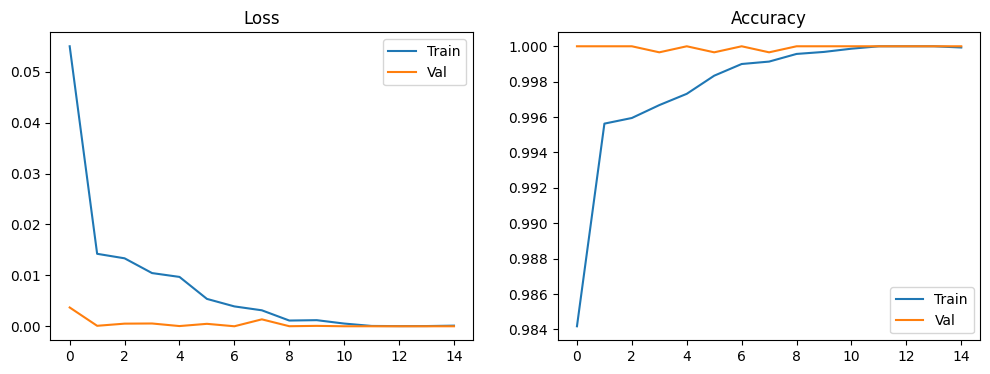

In [ ]:
# Cell 11: Plot curves
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(history["train_loss"], label="Train")
axs[0].plot(history["val_loss"], label="Val")
axs[0].set_title("Loss")
axs[0].legend()

axs[1].plot(history["train_acc"], label="Train")
axs[1].plot(history["val_acc"], label="Val")
axs[1].set_title("Accuracy")
axs[1].legend()

plt.show()


Test Loss: 0.0038 | Test Acc: 1.0000
              precision    recall  f1-score   support

 Cerscospora       1.00      1.00      1.00       768
     Healthy       1.00      1.00      1.00      1898
   Leaf rust       1.00      1.00      1.00       833
       Miner       1.00      1.00      1.00      1697
       Phoma       1.00      1.00      1.00       657

    accuracy                           1.00      5853
   macro avg       1.00      1.00      1.00      5853
weighted avg       1.00      1.00      1.00      5853



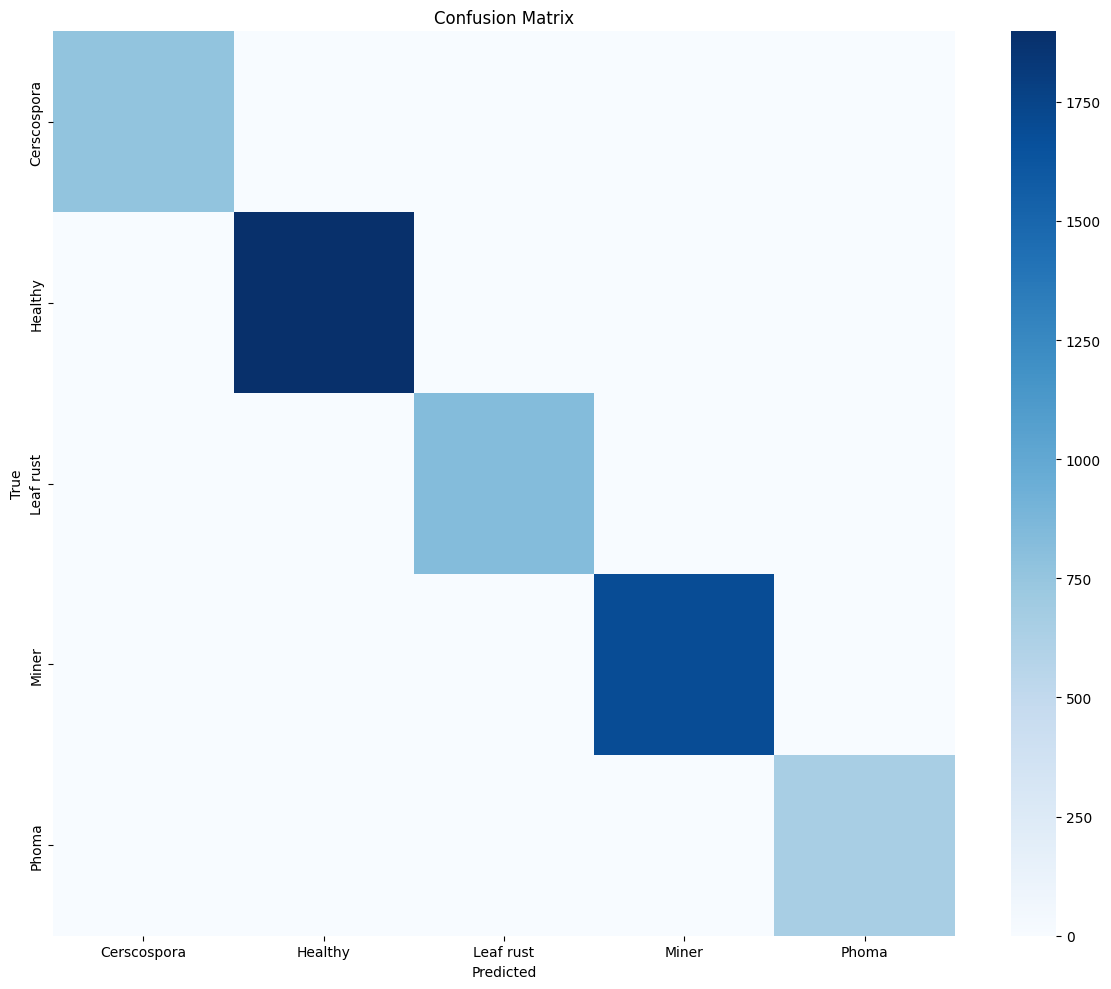

In [ ]:
# Cell 12: Test set evaluation
test_loss, test_acc, test_preds, test_labels = evaluate(resnet50, test_loader, criterion)
print(f"Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.4f}")

target_names = [idx_to_class[i] for i in range(len(idx_to_class))]
print(classification_report(test_labels, test_preds, target_names=target_names))

cm = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, cmap="Blues", xticklabels=target_names, yticklabels=target_names)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()


In [ ]:
import torch
from pathlib import Path

SAVE_DIR = Path("/content/artifacts")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = SAVE_DIR / "reducedcoffeedataset.pth"

checkpoint = {
    "model_state_dict": resnet50.state_dict(),
    "class_to_idx": class_to_idx,
    "idx_to_class": {v: k for k, v in class_to_idx.items()},
    "arch": "resnet50"
}

torch.save(checkpoint, MODEL_PATH)

print("Saved full checkpoint to:", MODEL_PATH)


Saved full checkpoint to: /content/artifacts/reducedcoffeedataset.pth
